# Part 2: Search interest vs. stock volatility
Pearson and Spearman only. Reads the weekly Google Trends CSVs in `data/googletrends/`, pulls daily prices from yfinance, builds weekly realized volatility, and tests whether *changes* in mean search interest are related to (or lead) *changes* in volatility.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import yfinance as yf
from scipy import stats

warnings.filterwarnings("ignore")

# ---------------- settings ----------------
TRENDS_DIR = Path("data/googletrends")
OUT_DIR    = Path("data/results")
PLOT_DIR   = OUT_DIR / "plots"
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

MAX_LAG     = 4      # test search changes lagged 1..MAX_LAG weeks
ALPHA       = 0.05
MIN_OBS     = 30     # min usable weeks to compute a company's stats
MIN_DAYS    = 3      # min trading days for a week's volatility to count
PLOT_ALL    = True   # set False to skip per-stock plots (500 figures take a few minutes)
OVERWRITE_PLOTS = False

# Only weeks that have fully ended (Sunday-Saturday) are used.
# Override with e.g. pd.Timestamp("2026-11-01") if you want a fixed cutoff.
PULL_DATE = pd.Timestamp.today().normalize()

## 1. Load Google Trends data

In [2]:
def week_start(idx):
    # Google Trends weeks run Sunday-Saturday; label each date by its Sunday
    idx = pd.DatetimeIndex(idx).normalize()
    return idx - pd.to_timedelta((idx.weekday + 1) % 7, unit="D")

def load_trends(path):
    df = pd.read_csv(path)
    df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]
    df = df.drop(columns=[c for c in df.columns if c.lower() == "ispartial"], errors="ignore")
    df["date"] = week_start(pd.to_datetime(df["date"]))
    return df.set_index("date").sort_index().apply(pd.to_numeric, errors="coerce")

trends = {p.stem: load_trends(p) for p in sorted(TRENDS_DIR.glob("*.csv"))}
print(f"{len(trends)} companies loaded")
t0 = next(iter(trends))
print(t0, trends[t0].index.min().date(), "->", trends[t0].index.max().date())
trends[t0].head()

500 companies loaded
A 2024-10-27 -> 2026-11-01


,chromatography,diagnostics,spectrometry,pharmaceutical
date,,,,
2024-10-27,7,72,2,18
2024-11-03,7,68,2,19
2024-11-10,7,73,2,21
2024-11-17,7,73,3,20
2024-11-24,4,57,2,14


## 2. Daily prices and weekly realized volatility

In [3]:
all_dates = pd.DatetimeIndex(sorted(set().union(*[df.index for df in trends.values()])))
start = (all_dates.min() - pd.Timedelta(days=10)).strftime("%Y-%m-%d")   # extra days so first week has a prior close
end   = (min(all_dates.max() + pd.Timedelta(days=14), PULL_DATE + pd.Timedelta(days=1))).strftime("%Y-%m-%d")

def download_prices(tickers, start, end, chunk=50):
    frames = []
    for i in range(0, len(tickers), chunk):
        batch = tickers[i:i + chunk]
        ymap = {t.replace(".", "-"): t for t in batch}     # BRK.B -> BRK-B
        raw = yf.download(list(ymap), start=start, end=end, auto_adjust=True,
                          progress=False, threads=True)["Close"]
        if isinstance(raw, pd.Series):
            raw = raw.to_frame(list(ymap)[0])
        frames.append(raw.rename(columns=ymap))
    return pd.concat(frames, axis=1)

daily_close = download_prices(list(trends), start, end)
missing = [t for t in trends if t not in daily_close.columns or daily_close[t].dropna().empty]
print(f"prices for {daily_close.shape[1]} tickers; no price data for: {missing}")
daily_close.tail(3)

prices for 500 tickers; no price data for: []


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2026-11-11,176.949997,355.359985,294.980011,181.130005,109.290001,109.169998,253.660004,237.600006,409.079987,70.919998,...,20.650000,85.379997,81.099998,166.710007,95.110001,85.720001,160.210007,107.470001,327.440002,82.570000
2026-11-12,173.009995,354.880005,294.450012,181.130005,107.250000,109.239998,249.949997,238.539993,409.290009,70.970001,...,20.459999,83.019997,81.500000,169.779999,94.029999,82.260002,159.339996,104.559998,317.829987,82.959999
2026-11-13,173.960007,356.269989,295.029999,186.779999,108.519997,109.610001,250.490005,243.080002,397.970001,72.900002,...,20.809999,85.059998,81.610001,170.589996,94.180000,84.580002,161.330002,103.209999,324.000000,83.820000


In [4]:
last_complete_week = week_start([PULL_DATE])[0] - pd.Timedelta(days=7)   # most recent Sunday whose Saturday has passed

def weekly_vol(close):
    close = close.dropna()
    r = np.log(close / close.shift(1)).dropna()
    wk = week_start(r.index)
    vol = np.sqrt((r ** 2).groupby(wk).sum())          # realized volatility
    n   = r.groupby(wk).size()
    return vol[n >= MIN_DAYS]

def weekly_price(close):
    close = close.dropna()
    return close.groupby(week_start(close.index)).last()

vol_w, price_w = {}, {}
for t in daily_close.columns:
    s = daily_close[t].dropna()
    if len(s) > 20:
        vol_w[t], price_w[t] = weekly_vol(s), weekly_price(s)
print(len(vol_w), "tickers with weekly volatility")

500 tickers with weekly volatility


## 3. Build one aligned weekly table per company
Each term is rescaled to 0-100 by its own max, averaged into `search`, and both `search` and `vol` are first-differenced (`d_search`, `d_vol`). The table is reindexed to a complete weekly calendar so that differences and lags never span a gap.

In [5]:
def build_company(t):
    tr = trends[t]
    tr = tr[tr.index <= last_complete_week]
    scaled = tr.div(tr.max().replace(0, np.nan)) * 100      # each term -> 0..100 of its own max
    scaled = scaled.dropna(axis=1, how="all")
    if scaled.shape[1] == 0 or t not in vol_w:
        return None, None
    df = pd.DataFrame({"search": scaled.mean(axis=1),
                       "vol":    vol_w[t],
                       "price":  price_w[t]})
    df = df.loc[df["search"].first_valid_index():df["search"].last_valid_index()]
    df = df.reindex(pd.date_range(df.index.min(), df.index.max(), freq="7D"))
    df["d_search"] = df["search"].diff()
    df["d_vol"]    = df["vol"].diff()
    return df, scaled

panels, scaled_terms = {}, {}
for t in trends:
    df, sc = build_company(t)
    if df is not None:
        panels[t], scaled_terms[t] = df, sc
print(len(panels), "companies with usable data")
panels[next(iter(panels))].tail()

500 companies with usable data


,search,vol,price,d_search,d_vol
2026-10-04,47.969697,0.027508,170.539993,-3.468254,-0.012325
2026-10-11,45.300144,0.022685,172.970001,-2.669553,-0.004823
2026-10-18,51.072872,0.043413,173.070007,5.772727,0.020728
2026-10-25,46.343795,0.045734,174.869995,-4.729076,0.002321
2026-11-01,44.903319,0.044935,174.759995,-1.440476,-0.000799


## 4. Per-company Pearson and Spearman correlations (same week and lagged)

In [6]:
def safe_corr(x, y):
    m = x.notna() & y.notna()
    if m.sum() < MIN_OBS or x[m].std() == 0 or y[m].std() == 0:
        return (np.nan, np.nan, np.nan, np.nan, int(m.sum()))
    pr, pp = stats.pearsonr(x[m], y[m])
    sr, sp = stats.spearmanr(x[m], y[m])
    return (pr, pp, sr, sp, int(m.sum()))

rows = []
for t, df in panels.items():
    x, y = df["d_search"], df["d_vol"]
    row = {"ticker": t}
    for k in range(0, MAX_LAG + 1):
        pr, pp, sr, sp, n = safe_corr(x.shift(k), y)       # search change from k weeks earlier
        row.update({f"pearson_r_lag{k}": pr, f"pearson_p_lag{k}": pp,
                    f"spearman_r_lag{k}": sr, f"spearman_p_lag{k}": sp, f"n_lag{k}": n})
    rows.append(row)

res = pd.DataFrame(rows).set_index("ticker")
res.to_csv(OUT_DIR / "per_company_results.csv")
res[["pearson_r_lag0", "pearson_p_lag0", "spearman_r_lag0", "spearman_p_lag0", "n_lag0"]].head(10)

,pearson_r_lag0,pearson_p_lag0,spearman_r_lag0,spearman_p_lag0,n_lag0
ticker,,,,,
A,0.039607,0.688306,0.045781,0.642834,105
AAPL,0.020538,0.835265,-0.029944,0.761714,105
ABBV,0.097373,0.323063,0.028774,0.770766,105
ABNB,-0.022383,0.820701,0.059754,0.544838,105
ABT,-0.001503,0.987860,0.032786,0.739869,105
ACGL,0.059794,0.544569,0.068540,0.487223,105
ACN,0.172065,0.079234,0.086842,0.378384,105
ADBE,0.164692,0.093176,0.231886,0.017302,105
ADI,0.076098,0.440376,0.058916,0.550509,105


### Which companies dropped out? (for the Data section)

In [7]:
dropped = sorted((set(trends) - set(panels)) | set(res.index[res["pearson_r_lag0"].isna()]))
print("companies in the Trends folder:", len(trends))
print("companies with statistics:     ", int(res["pearson_r_lag0"].notna().sum()))
print("dropped:", dropped)
for t in dropped:
    if t not in panels:
        reason = "no price data" if t not in vol_w else "no usable search terms (all terms zero/empty)"
        print(f"  {t}: {reason}")
    else:
        p = panels[t]; ok = p["d_search"].notna() & p["d_vol"].notna()
        print(f"  {t}: usable weeks = {ok.sum()}, d_search std = {p['d_search'].std():.3f}, d_vol std = {p['d_vol'].std():.4f}")

companies in the Trends folder: 500
companies with statistics:      497
dropped: ['FDXF', 'HONA', 'VYLR']
  FDXF: usable weeks = 22, d_search std = 5.912, d_vol std = 0.0382
  HONA: usable weeks = 20, d_search std = 3.743, d_vol std = 0.0889
  VYLR: usable weeks = 4, d_search std = 3.712, d_vol std = 0.0352


## 5. Summary across companies

In [8]:
rows = []
for k in range(0, MAX_LAG + 1):
    for kind in ("pearson", "spearman"):
        m = res[f"{kind}_p_lag{k}"].notna()
        r, p = res.loc[m, f"{kind}_r_lag{k}"], res.loc[m, f"{kind}_p_lag{k}"]
        n = len(r)
        sig = p < ALPHA
        rows.append({
            "test": kind, "search_lag_weeks": k, "companies": n,
            "mean_r": r.mean(), "median_r": r.median(), "share_positive": (r > 0).mean(),
            "sd_of_r": r.std(),
            "sd_if_pure_noise": 1 / np.sqrt(res.loc[m, f"n_lag{k}"].mean()),   # approx. spread of r if there were no relationship
            "sig_raw": int(sig.sum()), "sig_positive": int((sig & (r > 0)).sum()),
            "sig_negative": int((sig & (r < 0)).sum()),
            "expected_by_chance": round(ALPHA * n, 1),
        })
summary = pd.DataFrame(rows)
summary.to_csv(OUT_DIR / "summary_by_lag.csv", index=False)
summary.round(4)

,test,search_lag_weeks,companies,mean_r,median_r,share_positive,sd_of_r,sd_if_pure_noise,sig_raw,sig_positive,sig_negative,expected_by_chance
0,pearson,0,497,0.0538,0.0552,0.7002,0.1079,0.0977,55,44,11,24.9
1,spearman,0,497,0.0579,0.0605,0.7022,0.1060,0.0977,60,54,6,24.9
2,pearson,1,497,0.0162,0.0137,0.5654,0.0999,0.0981,29,22,7,24.9
3,spearman,1,497,0.0212,0.0160,0.5714,0.1054,0.0981,43,30,13,24.9
4,pearson,2,497,-0.0236,-0.0138,0.4527,0.1030,0.0986,35,10,25,24.9
5,spearman,2,497,-0.0218,-0.0184,0.4326,0.1135,0.0986,47,13,34,24.9
6,pearson,3,497,-0.0127,-0.0145,0.4487,0.0995,0.0991,28,11,17,24.9
7,spearman,3,497,-0.0182,-0.0175,0.4467,0.0985,0.0991,29,6,23,24.9
8,pearson,4,497,0.0175,0.0204,0.5976,0.0953,0.0996,24,18,6,24.9
9,spearman,4,497,0.0097,0.0106,0.5312,0.1000,0.0996,26,16,10,24.9


In [9]:
# Table 1 for the write-up
pe = summary[summary.test == "pearson"].set_index("search_lag_weeks")
sp = summary[summary.test == "spearman"].set_index("search_lag_weeks")
table1 = pd.DataFrame({
    "Pearson mean r":        pe["mean_r"].round(3),
    "Pearson % positive":    (pe["share_positive"] * 100).round(1),
    "Pearson sig. (n)":      pe["sig_raw"],
    "Spearman mean r":       sp["mean_r"].round(3),
    "Spearman % positive":   (sp["share_positive"] * 100).round(1),
    "Spearman sig. (n)":     sp["sig_raw"],
    "Expected by chance":    pe["expected_by_chance"],
})
table1.index.name = "Search lag (weeks)"
table1.to_csv(OUT_DIR / "table1.csv")
table1

,Pearson mean r,Pearson % positive,Pearson sig. (n),Spearman mean r,Spearman % positive,Spearman sig. (n),Expected by chance
Search lag (weeks),,,,,,,
0,0.054,70.0,55,0.058,70.2,60,24.9
1,0.016,56.5,29,0.021,57.1,43,24.9
2,-0.024,45.3,35,-0.022,43.3,47,24.9
3,-0.013,44.9,28,-0.018,44.7,29,24.9
4,0.018,59.8,24,0.010,53.1,26,24.9


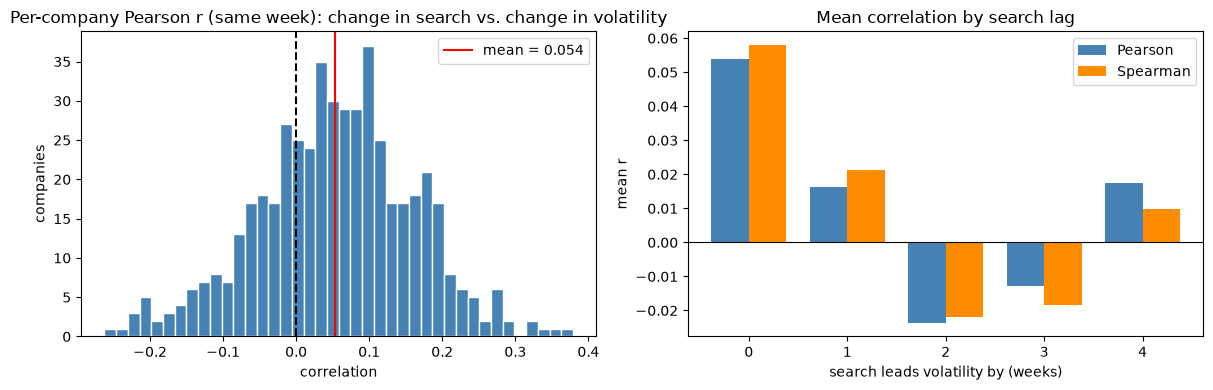

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
r0 = res["pearson_r_lag0"].dropna()
axes[0].hist(r0, bins=40, color="steelblue", edgecolor="white")
axes[0].axvline(0, color="k", ls="--"); axes[0].axvline(r0.mean(), color="red", label=f"mean = {r0.mean():.3f}")
axes[0].set(title="Per-company Pearson r (same week): change in search vs. change in volatility",
            xlabel="correlation", ylabel="companies"); axes[0].legend()

w = 0.38
axes[1].bar(pe.index - w/2, pe["mean_r"], w, label="Pearson", color="steelblue")
axes[1].bar(sp.index + w/2, sp["mean_r"], w, label="Spearman", color="darkorange")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(title="Mean correlation by search lag", xlabel="search leads volatility by (weeks)", ylabel="mean r")
axes[1].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "summary_plots.png", dpi=150); plt.show()

## 6. Per-stock plots (saved to `data/results/plots/`)

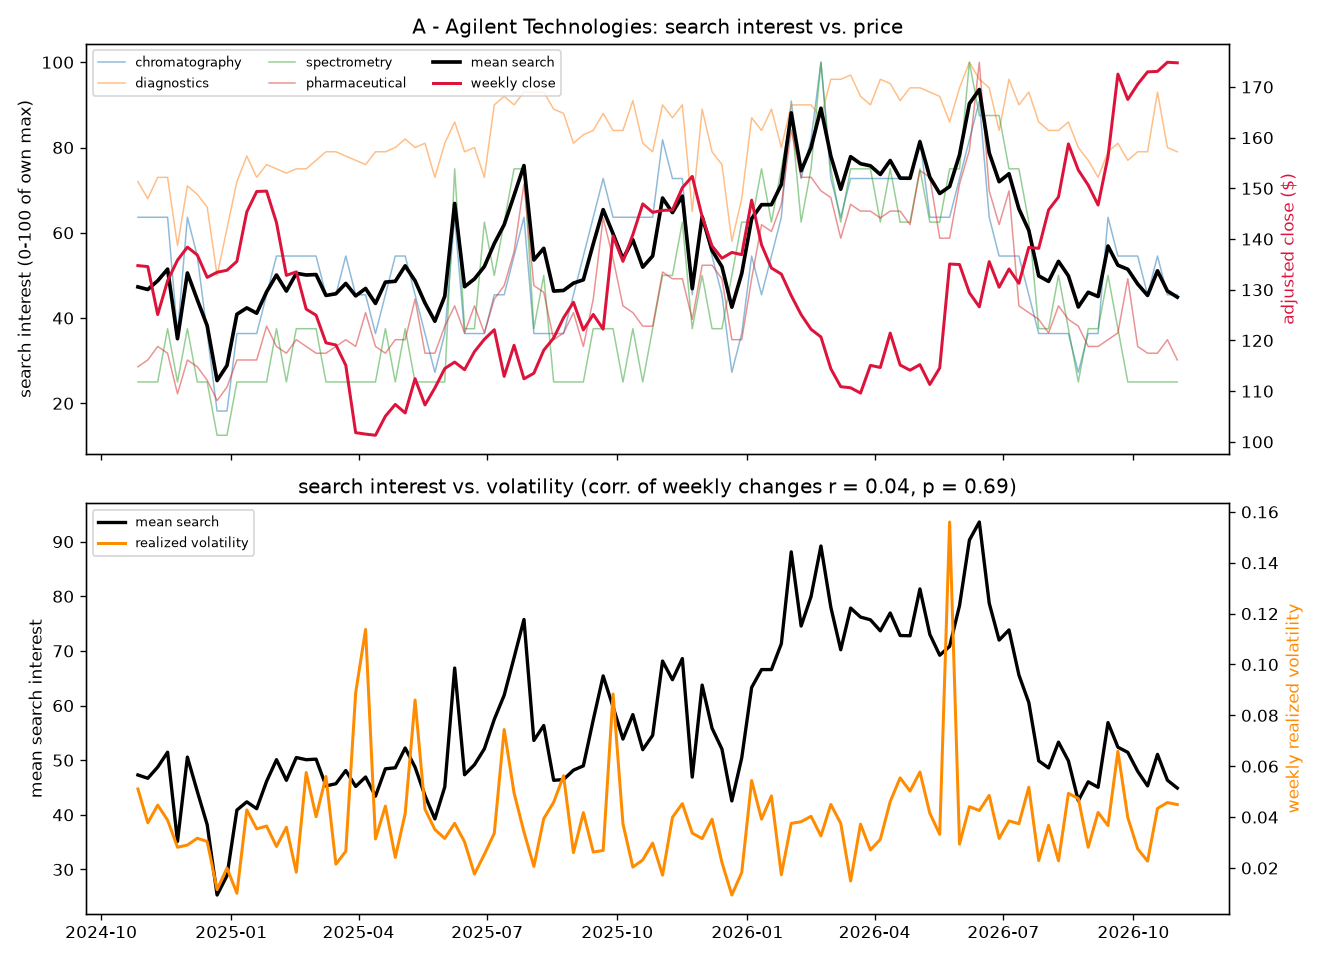

In [11]:
# Company names: Wikipedia table (one request), cached to disk; falls back to ticker only
NAMES_CSV = OUT_DIR / "company_names.csv"
def get_names():
    if NAMES_CSV.exists():
        return pd.read_csv(NAMES_CSV, index_col=0)["name"].to_dict()
    try:
        import requests, io
        html = requests.get("https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
                            headers={"User-Agent": "Mozilla/5.0 (class project)"}, timeout=20).text
        tbl = pd.read_html(io.StringIO(html))[0]
        names = dict(zip(tbl["Symbol"].str.strip(), tbl["Security"].str.strip()))
        pd.Series(names, name="name").to_csv(NAMES_CSV)
        return names
    except Exception as e:
        print("Could not fetch company names:", e)
        return {}
names = get_names()

def plot_company(t):
    df, sc = panels[t], scaled_terms[t]
    name = names.get(t, names.get(t.replace("-", "."), ""))
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # top: search terms + mean vs price
    for c in sc.columns:
        a1.plot(sc.index, sc[c], lw=0.9, alpha=0.5, label=c)
    a1.plot(df.index, df["search"], color="black", lw=2.2, label="mean search")
    a1.set_ylabel("search interest (0-100 of own max)")
    b1 = a1.twinx()
    b1.plot(df.index, df["price"], color="crimson", lw=1.8, label="weekly close")
    b1.set_ylabel("adjusted close ($)", color="crimson")
    h1, l1 = a1.get_legend_handles_labels(); h2, l2 = b1.get_legend_handles_labels()
    a1.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left", ncol=3)
    a1.set_title(f"{t} - {name}: search interest vs. price")

    # bottom: mean search vs realized volatility
    a2.plot(df.index, df["search"], color="black", lw=2, label="mean search")
    a2.set_ylabel("mean search interest")
    b2 = a2.twinx()
    b2.plot(df.index, df["vol"], color="darkorange", lw=1.8, label="realized volatility")
    b2.set_ylabel("weekly realized volatility", color="darkorange")
    r = res.loc[t, "pearson_r_lag0"] if t in res.index else np.nan
    p = res.loc[t, "pearson_p_lag0"] if t in res.index else np.nan
    a2.set_title(f"search interest vs. volatility (corr. of weekly changes r = {r:.2f}, p = {p:.2f})")
    h1, l1 = a2.get_legend_handles_labels(); h2, l2 = b2.get_legend_handles_labels()
    a2.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")

    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{t}.png", dpi=120)
    plt.close(fig)

# look at one first
t_demo = next(iter(panels)); plot_company(t_demo)
from IPython.display import Image, display
display(Image(filename=str(PLOT_DIR / f"{t_demo}.png")))

In [12]:
if PLOT_ALL:
    matplotlib.use("Agg")      # don't render each figure in the notebook
    for i, t in enumerate(panels, 1):
        if OVERWRITE_PLOTS or not (PLOT_DIR / f"{t}.png").exists():
            plot_company(t)
        if i % 50 == 0:
            print(f"{i}/{len(panels)} plots done")
    print("done")

50/500 plots done
100/500 plots done
150/500 plots done
200/500 plots done
250/500 plots done
300/500 plots done
350/500 plots done
400/500 plots done
450/500 plots done
500/500 plots done
done


## 7. Headline numbers

In [13]:
for kind in ("pearson", "spearman"):
    s = summary[(summary.test == kind) & (summary.search_lag_weeks == 0)].iloc[0]
    print(f"{kind.title():9s} same week: mean r = {s.mean_r:.3f}, median = {s.median_r:.3f}, "
          f"{s.share_positive:.0%} positive | significant {s.sig_raw} of {s.companies} "
          f"(expected by chance {s.expected_by_chance}; {s.sig_positive} positive / {s.sig_negative} negative)")
    print(f"{'':9s} spread of r across companies = {s.sd_of_r:.3f} vs {s.sd_if_pure_noise:.3f} if pure noise")

Pearson   same week: mean r = 0.054, median = 0.055, 70% positive | significant 55 of 497 (expected by chance 24.9; 44 positive / 11 negative)
          spread of r across companies = 0.108 vs 0.098 if pure noise
Spearman  same week: mean r = 0.058, median = 0.060, 70% positive | significant 60 of 497 (expected by chance 24.9; 54 positive / 6 negative)
          spread of r across companies = 0.106 vs 0.098 if pure noise


## 8. Post-Run Figure Generator

497 companies in the analysis panel


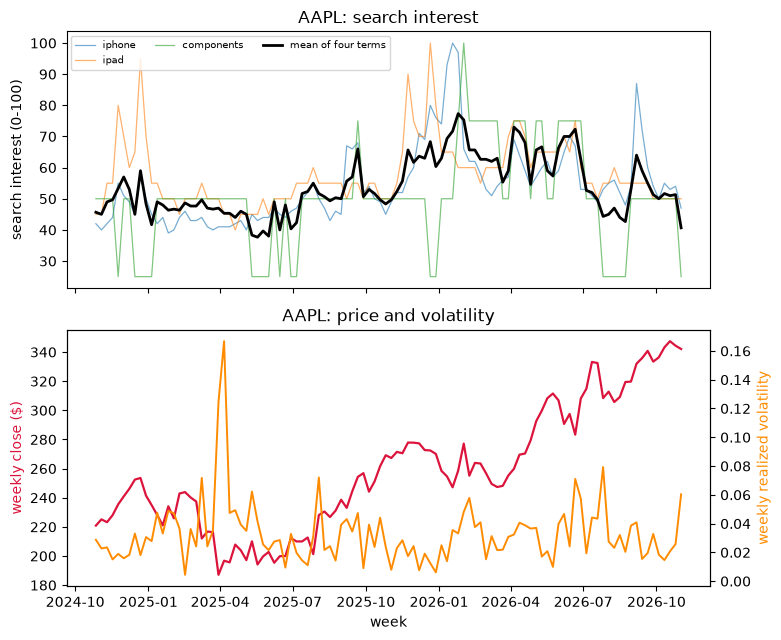

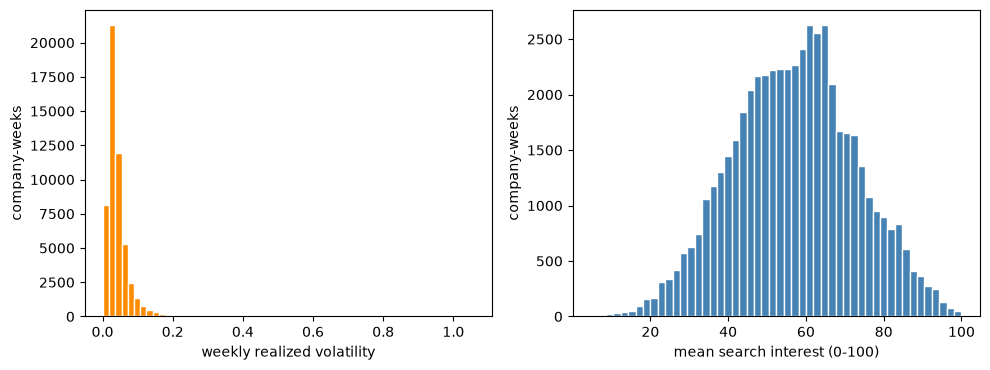

skewness: volatility = 3.76, search = -0.01  (positive = right-skewed)
Weekly realized volatility & 0.0420 & 0.0316 & 0.0337 & 52,614 \\
Mean search interest (0--100) & 56.94 & 15.80 & 57.33 & 52,682 \\
Weeks per company & 105.9 & 2.4 & 106 & 497 \\
0 & 44 & 11 & 54 & 6 & 24.9 \\
1 & 22 & 7 & 30 & 13 & 24.9 \\
2 & 10 & 25 & 13 & 34 & 24.9 \\
3 & 11 & 17 & 6 & 23 & 24.9 \\
4 & 18 & 6 & 16 & 10 & 24.9 \\


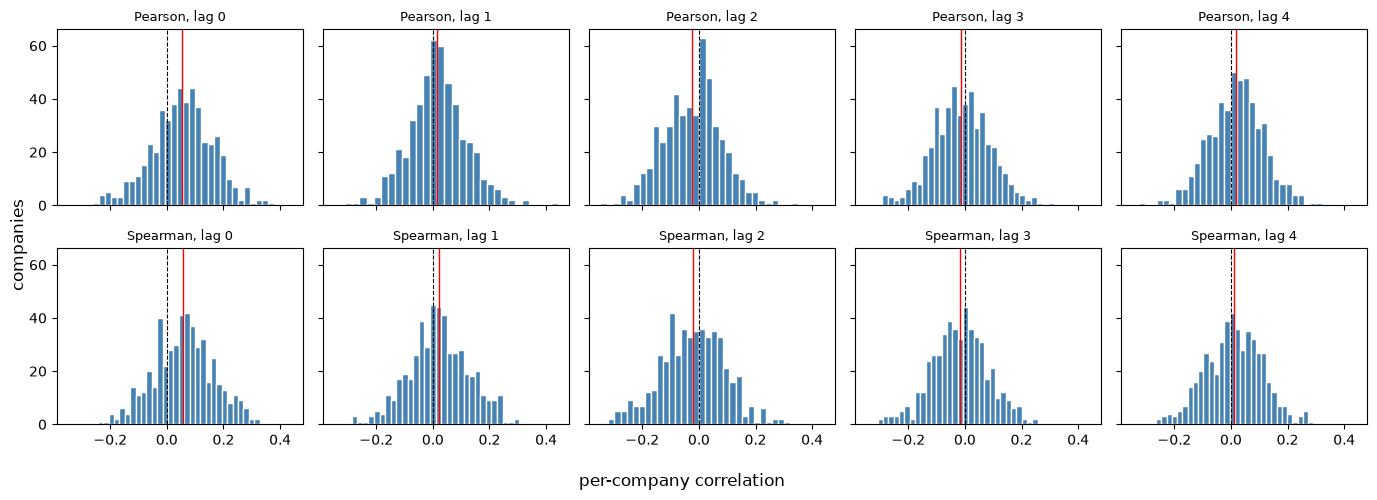

In [14]:
# ===== Report figures and tables (paste as a new cell at the END of the notebook) =====
# Needs: panels, scaled_terms, res, summary, OUT_DIR, ALPHA, MAX_LAG from the earlier cells.
import shutil
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")   # an earlier cell switched to the Agg backend
except NameError:
    pass
import matplotlib.pyplot as plt

FIG_DIR = Path("figure"); FIG_DIR.mkdir(exist_ok=True)          # the folder the LaTeX file reads from
EXAMPLE = "AAPL" if "AAPL" in panels else next(iter(panels))     # change to any ticker you like
kept = list(res.index[res["pearson_r_lag0"].notna()])            # the companies actually analysed (497)
print(len(kept), "companies in the analysis panel")

# ---------- Figure: example company (figure/example_company.pdf) ----------
df, sc = panels[EXAMPLE], scaled_terms[EXAMPLE]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True)
for c in sc.columns:
    a1.plot(sc.index, sc[c], lw=0.9, alpha=0.6, label=c)
a1.plot(df.index, df["search"], color="black", lw=2, label="mean of four terms")
a1.set_ylabel("search interest (0-100)"); a1.legend(fontsize=7, ncol=3, loc="upper left")
a1.set_title(f"{EXAMPLE}: search interest")
a2.plot(df.index, df["price"], color="crimson", lw=1.6)
a2.set_ylabel("weekly close ($)", color="crimson")
b2 = a2.twinx(); b2.plot(df.index, df["vol"], color="darkorange", lw=1.4)
b2.set_ylabel("weekly realized volatility", color="darkorange")
a2.set_title(f"{EXAMPLE}: price and volatility"); a2.set_xlabel("week")
fig.tight_layout(); fig.savefig(FIG_DIR / "example_company.pdf"); plt.show()

# ---------- Figure: histograms of volatility and search (figure/histograms.pdf) ----------
vol_all    = pd.concat([panels[t]["vol"] for t in kept]).dropna()
search_all = pd.concat([panels[t]["search"] for t in kept]).dropna()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(vol_all, bins=60, color="darkorange", edgecolor="white")
axes[0].set(xlabel="weekly realized volatility", ylabel="company-weeks")
axes[1].hist(search_all, bins=50, color="steelblue", edgecolor="white")
axes[1].set(xlabel="mean search interest (0-100)", ylabel="company-weeks")
fig.tight_layout(); fig.savefig(FIG_DIR / "histograms.pdf"); plt.show()
print(f"skewness: volatility = {stats.skew(vol_all):.2f}, search = {stats.skew(search_all):.2f}  (positive = right-skewed)")

# ---------- Figure: main results figure (corr_figure.png) ----------
shutil.copy(OUT_DIR / "summary_plots.png", FIG_DIR / "corr_figure.png")

# ---------- Table: summary statistics (paste rows into Table 'tab:summary') ----------
weeks = pd.Series({t: int(panels[t][["search", "vol"]].notna().all(axis=1).sum()) for t in kept})
def row(label, s, d):
    return f"{label} & {s.mean():.{d}f} & {s.std():.{d}f} & {s.median():.{d}f} & {len(s):,} \\\\"
print(row("Weekly realized volatility", vol_all, 4))
print(row("Mean search interest (0--100)", search_all, 2))
print(f"Weeks per company & {weeks.mean():.1f} & {weeks.std():.1f} & {weeks.median():.0f} & {len(weeks)} \\\\")

# ---------- Appendix table: significant companies by sign (paste rows into a new table) ----------
for k in range(MAX_LAG + 1):
    p = summary[(summary.test == "pearson") & (summary.search_lag_weeks == k)].iloc[0]
    s = summary[(summary.test == "spearman") & (summary.search_lag_weeks == k)].iloc[0]
    print(f"{k} & {p.sig_positive} & {p.sig_negative} & {s.sig_positive} & {s.sig_negative} & {p.expected_by_chance} \\\\")

# ---------- Appendix figure: correlation distributions at every lag (figure/corr_by_lag.pdf) ----------
fig, axes = plt.subplots(2, MAX_LAG + 1, figsize=(14, 5), sharex=True, sharey=True)
for j, kind in enumerate(("pearson", "spearman")):
    for k in range(MAX_LAG + 1):
        r = res.loc[kept, f"{kind}_r_lag{k}"].dropna()
        axes[j, k].hist(r, bins=30, color="steelblue", edgecolor="white")
        axes[j, k].axvline(0, color="k", ls="--", lw=0.8)
        axes[j, k].axvline(r.mean(), color="red", lw=1)
        axes[j, k].set_title(f"{kind.title()}, lag {k}", fontsize=9)
fig.supxlabel("per-company correlation"); fig.supylabel("companies")
fig.tight_layout(); fig.savefig(FIG_DIR / "corr_by_lag.pdf"); plt.show()